# 01 · Exploration of the job corpus

What is in the data the system searches? Sources, completeness of the extracted fields, skill demand, skill associations and role profiles. Data: `data/processed/jobs_enriched.jsonl` and `data/jobintel.db` (created by `jobintel collect && jobintel enrich`).

In [1]:
import os, sys, json, sqlite3
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#2a78d6"


In [2]:
from job_intel.enrich.postings import load_postings
from job_intel.market import analytics as ma
postings = load_postings(Path("data/processed/jobs_enriched.jsonl"))
df = ma.postings_frame(postings)
print(len(df), "listings,", df.company.nunique(), "companies")
df.source.value_counts()

720 listings, 490 companies


source
himalayas    515
arbeitnow    204
remotive       1
Name: count, dtype: int64

## Field completeness
Unknown stays unknown: the share of listings where each structured field could be read.

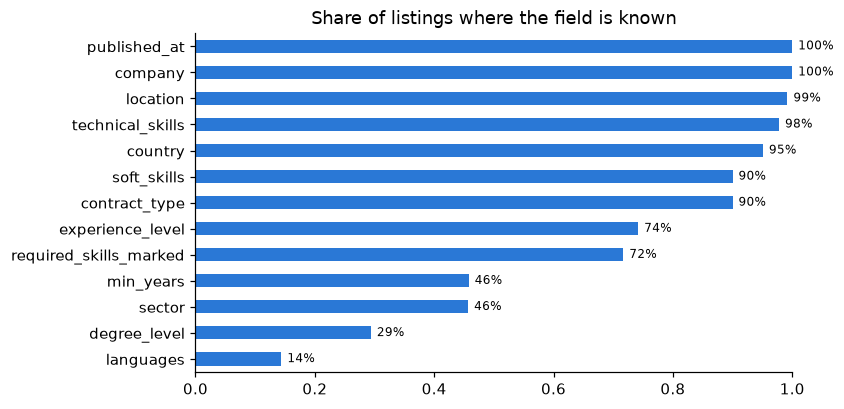

In [3]:
q = json.loads(Path("data/processed/quality_report.json").read_text())["completeness"]
s = pd.Series(q).sort_values()
ax = s.plot.barh(color=BLUE, figsize=(7, 4)); ax.set_xlim(0, 1); ax.set_title("Share of listings where the field is known")
for i, v in enumerate(s): ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8)
plt.show()

## Skill demand (SQL on the SQLite store)

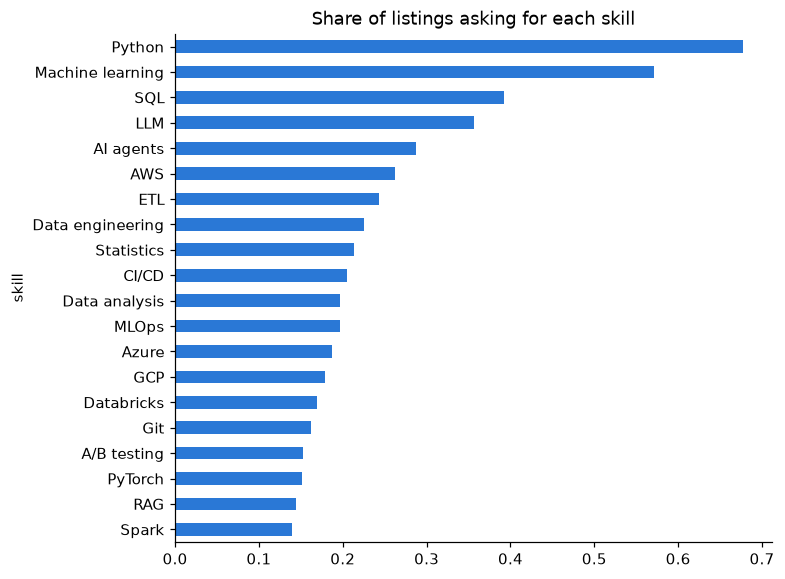

,skill,listings,share
0,Python,488,0.677778
1,Machine learning,411,0.570833
2,SQL,282,0.391667
3,LLM,257,0.356944
4,AI agents,207,0.287500
5,AWS,189,0.262500
6,ETL,175,0.243056
7,Data engineering,162,0.225000
8,Statistics,154,0.213889
9,CI/CD,148,0.205556


In [4]:
con = sqlite3.connect("data/jobintel.db")
top = pd.read_sql("SELECT skill, COUNT(DISTINCT job_id) AS listings FROM job_skills GROUP BY skill ORDER BY listings DESC LIMIT 20", con)
top["share"] = top.listings / len(df)
ax = top[::-1].plot.barh(x="skill", y="share", color=BLUE, legend=False, figsize=(7, 6)); ax.set_title("Share of listings asking for each skill")
plt.show(); top.head(10)

## Required vs merely mentioned
The extractor separates *required* (requirements section or cue words) from *preferred* and *mentioned*.

In [5]:
pd.read_sql("SELECT level, COUNT(*) AS n FROM job_skills GROUP BY level", con)

,level,n
0,mentioned,1797
1,preferred,1002
2,required,3478


## Skill associations: lift
`lift(A,B) = P(A,B) / (P(A)P(B))` - above 1 means asked together more often than chance.

In [6]:
ma.cooccurrence(df, top_skills=25, min_count=10).head(12)

,a,b,count,p_b_given_a,lift
0,Docker,Kubernetes,48,0.600000,5.082353
1,Deep learning,NLP,37,0.389474,3.378567
2,Azure,GCP,81,0.600000,3.348837
3,Docker,MLOps,51,0.637500,3.232394
4,Prompt engineering,RAG,42,0.466667,3.230769
5,CI/CD,Docker,52,0.351351,3.162162
6,CI/CD,Kubernetes,55,0.371622,3.147854
7,Kubernetes,MLOps,51,0.600000,3.042254
8,NLP,PyTorch,38,0.457831,3.024207
9,GCP,Kubernetes,45,0.348837,2.954856


## What characterises each role family? (distinctiveness = P(skill | family) / P(skill))

In [7]:
prof = ma.role_profiles(df)
prof.groupby("role_family").head(4)[["role_family", "skill", "share_in_family", "distinctiveness"]]

,role_family,skill,share_in_family,distinctiveness
0,AI engineer,Prompt engineering,0.330000,2.640000
1,AI engineer,Vector database,0.170000,2.497959
2,AI engineer,TypeScript,0.140000,2.400000
3,AI engineer,LangChain,0.145000,2.320000
8,Data analyst,Excel,0.271186,8.135593
9,Data analyst,Power BI,0.355932,4.745763
10,Data analyst,Tableau,0.372881,3.890936
11,Data analyst,Data analysis,0.661017,3.351635
16,Data engineer,dbt,0.425532,4.085106
17,Data engineer,Redshift,0.120567,3.617021


## Countries and experience levels
Himalayas is remote-only and US-heavy: this is a sample of three boards, not the labour market.

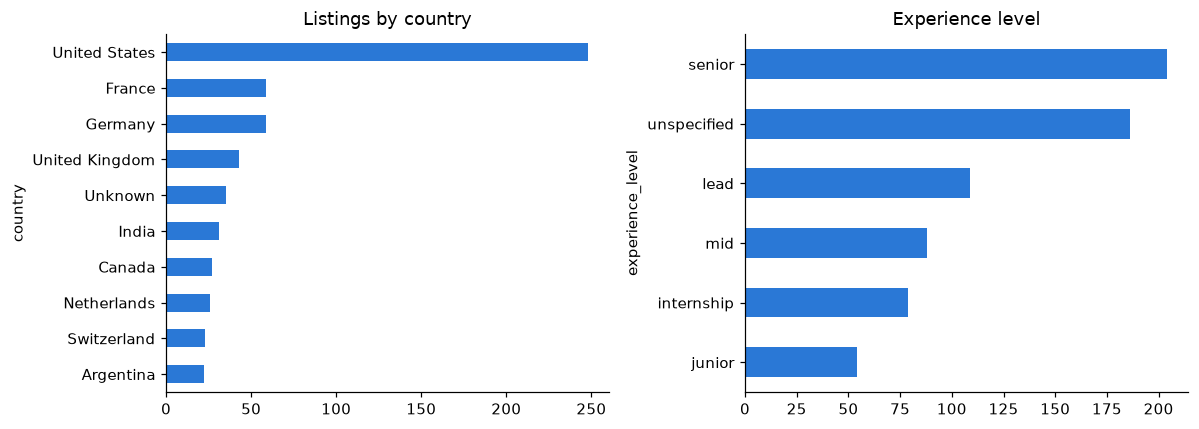

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ma.counts_by(df, "country", 10).set_index("country").postings[::-1].plot.barh(ax=axes[0], color=BLUE, title="Listings by country")
df.experience_level.value_counts()[::-1].plot.barh(ax=axes[1], color=BLUE, title="Experience level")
plt.tight_layout(); plt.show()